In [1]:
%pip install pandas numpy xarray netCDF4 matplotlib statsmodels patsy cdsapi

import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import statsmodels.api as sm
import patsy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Load the London daily dataset (Bhaskaran et al. 2013)
df = pd.read_stata("data/londondataset2002_2006.dta")

print(df.shape)     # rows, columns
print(df.dtypes)    # column names and types
df.head()

(1826, 5)
date                 datetime64[ns]
ozone                       float32
temperature                 float32
relative_humidity           float32
numdeaths                     int16
dtype: object


,date,ozone,temperature,relative_humidity,numdeaths
0,2002-01-01,4.586225,-0.2250,75.678299,199
1,2002-01-02,4.876853,0.0875,77.525002,231
2,2002-01-03,4.707875,0.8500,81.324997,210
3,2002-01-04,4.137461,0.5375,85.449997,203
4,2002-01-05,2.005846,4.2500,93.525002,224


In [3]:
# Replace "date" with the actual date column name if it differs
print(df["date"].min(), "to", df["date"].max())

expected_days = (df["date"].max() - df["date"].min()).days + 1
print("rows:", len(df), "| expected days:", expected_days)

2002-01-01 00:00:00 to 2006-12-31 00:00:00
rows: 1826 | expected days: 1826


In [4]:
print(df.columns.tolist())
df.describe().round(1)

['date', 'ozone', 'temperature', 'relative_humidity', 'numdeaths']


,date,ozone,temperature,relative_humidity,numdeaths
count,1826,1826.0,1826.0,1826.0,1826.0
mean,2004-07-01 12:00:00,34.8,11.7,69.1,149.5
min,2002-01-01 00:00:00,1.2,-1.4,31.2,99.0
25%,2003-04-02 06:00:00,21.1,7.5,58.7,135.0
50%,2004-07-01 12:00:00,34.9,11.5,69.6,148.0
75%,2005-09-30 18:00:00,46.7,16.2,80.4,162.0
max,2006-12-31 00:00:00,119.2,28.2,98.9,280.0
std,NaN,18.3,5.6,13.7,20.7


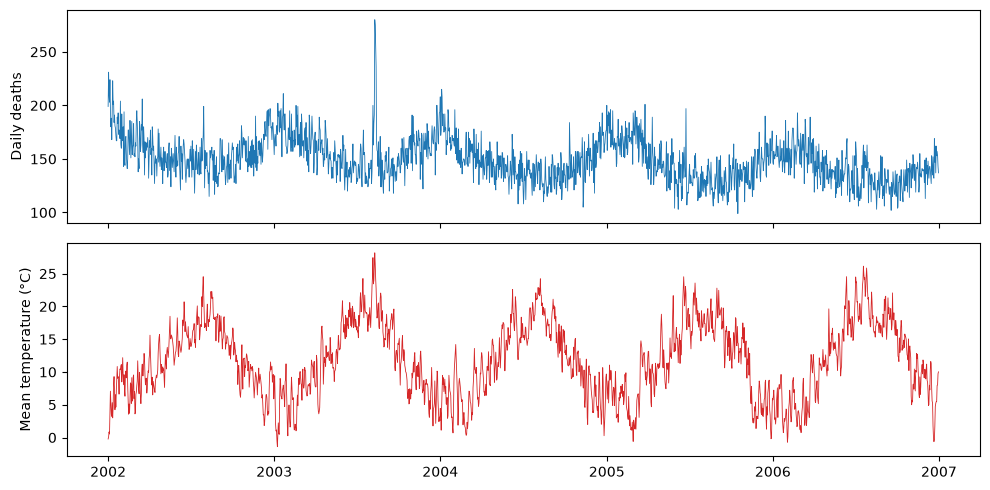

date           2003-08-10 00:00:00
temperature              28.174999
numdeaths                      280
Name: 586, dtype: object

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

axes[0].plot(df["date"], df["numdeaths"], lw=0.6)
axes[0].set_ylabel("Daily deaths")

axes[1].plot(df["date"], df["temperature"], lw=0.6, color="tab:red")
axes[1].set_ylabel("Mean temperature (°C)")

plt.tight_layout()
plt.show()

# Which day had the most deaths?
df.loc[df["numdeaths"].idxmax(), ["date", "temperature", "numdeaths"]]